# scNOMe-HiC GCH vs snATAC over DNase peaks -- R (smoothScatter style)

Per-peak GCH accessibility vs snATAC, plotted in the **same format** as
`single_cell_vs_bulk.ipynb` (base-R `smoothScatter`, blue density palette,
large fonts, dashed **y = x** diagonal, Pearson-*r* box, PDF + inline).

Inputs are the processed per-peak tables from the Python pipeline:
`data/peak_signal.tab` (chr,start,end,GCH%,snATAC CPM) and
`data/peak_gch_coverage.tab` (per-peak total GCH read coverage).

Because GCH (methylation %, 0-100) and snATAC (CPM) are on **different native
scales** (unlike the pooled-vs-bulk methylation in the reference, which share the
0-1 scale), we apply the reference's own classic **quantile normalization**, then
jointly rescale to [0,1] so the y=x diagonal is meaningful. Two panels:
all peaks, and peaks with **GCH coverage > 10**.

In [1]:
# --- repo paths: edit paths.yaml at the repository root, not this notebook ---
# Cached so that re-running this cell still works after it has setwd() away.
if (!exists(".repo_root")) {
  .r <- getwd()
  while (.r != "/" && !file.exists(file.path(.r, "paths.R"))) .r <- dirname(.r)
  stopifnot(file.exists(file.path(.r, "paths.R")))
  .repo_root <- .r
}
source(file.path(.repo_root, "paths.R"))

# ============================================================================
# LOAD + helpers.  Reads the per-peak tables once into `d`; defines the reference
# quantile_normalize() and a smoothScatter drawer matching single_cell_vs_bulk.ipynb.
# ============================================================================
suppressPackageStartupMessages(library(data.table))

DATA <- file.path(WORK, "analysis/s2_new/atac_dnase_gm12878/data")
FIG  <- file.path(WORK, "analysis/s2_new/atac_dnase_gm12878/figures")

ps <- fread(file.path(DATA, "peak_signal.tab"), skip = 1, header = FALSE,
            col.names = c("chr","start","end","GCH","snATAC"))
cv <- fread(file.path(DATA, "peak_gch_coverage.tab"), header = FALSE,
            col.names = c("chr","start","end","gch_cov","gch_nsites"))
d <- merge(ps, cv, by = c("chr","start","end"), all.x = TRUE)
d[, GCH := as.numeric(GCH)][, snATAC := as.numeric(snATAC)]
d <- d[is.finite(GCH) & is.finite(snATAC)]
cat(sprintf("loaded: %s peaks (GCH & snATAC finite); %s with GCH coverage > 10\n",
            format(nrow(d), big.mark = ","), format(sum(d$gch_cov > 10), big.mark = ",")))

# classic quantile normalization (verbatim from single_cell_vs_bulk.ipynb)
quantile_normalize <- function(matrix_data) {
  n_rows <- nrow(matrix_data); n_cols <- ncol(matrix_data)
  max_non_na <- max(colSums(!is.na(matrix_data)))
  sorted_matrix <- matrix(NA_real_, nrow = max_non_na, ncol = n_cols)
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; v <- sort(v[!is.na(v)])
    sorted_matrix[seq_along(v), i] <- v }
  row_means <- rowMeans(sorted_matrix, na.rm = TRUE)
  out <- matrix(NA_real_, nrow = n_rows, ncol = n_cols, dimnames = dimnames(matrix_data))
  for (i in seq_len(n_cols)) { v <- matrix_data[, i]; na <- is.na(v)
    out[!na, i] <- row_means[rank(v[!na], ties.method = "average")] }
  out
}

# QN a GCH/snATAC pair, then jointly rescale to [0,1] (monotone -> r unchanged)
qn01 <- function(gch, snat) {
  qn <- quantile_normalize(cbind(GCH = gch, snATAC = snat))
  rng <- range(qn, na.rm = TRUE)
  list(x = (qn[,1]-rng[1])/(rng[2]-rng[1]), y = (qn[,2]-rng[1])/(rng[2]-rng[1]))
}

bpalette <- colorRampPalette(c("white", "#deebf7", "#9ecae1", "#3182bd", "#08519c"))

# smoothScatter drawer in the reference's large-font style (x,y in [0,1])
draw_scatter <- function(x, y, xlab_txt, ylab_txt, out_base) {
  r_p <- cor(x, y); r_s <- cor(x, y, method = "spearman")
  cat(sprintf("%s   n = %s   Pearson r = %.3f   Spearman rho = %.3f\n",
              basename(out_base), format(length(x), big.mark = ","), r_p, r_s))
  annot <- sprintf("r: %.3f\nP < 2.2e-16", r_p)
  draw_one <- function() {
    par(mar = c(10, 10, 7, 10), mgp = c(6, 1.2, 0),
        cex.lab = 2.5, cex.axis = 2.5, family = "sans", tcl = -0.35, las = 1)
    smoothScatter(x, y, xlim = c(0, 1), ylim = c(0, 1), nrpoints = 0,
                  xlab = "", ylab = "", main = "", colramp = bpalette, axes = FALSE)
    axis(1, at = seq(0, 1, by = 0.25), lwd = 1, mgp = c(3, 1.2, 0))
    axis(2, at = seq(0, 1, by = 0.25), lwd = 1, las = 1, mgp = c(3.5, 0.9, 0))
    mtext(xlab_txt, side = 1, line = 5.0, cex = 2.8)
    mtext(ylab_txt, side = 2, line = 7,   cex = 2.8, las = 0)
    box(lwd = 1)
    abline(0, 1, lty = 2, lwd = 1.5, col = "grey35")
    text(0.02, 0.85, annot, pos = 4, cex = 3, font = 2)
  }
  fig_w <- 9.05; fig_h <- 8
  pdf(paste0(out_base, ".pdf"), width = fig_w, height = fig_h, useDingbats = FALSE, family = "Helvetica")
  draw_one(); dev.off()
  png(paste0(out_base, ".png"), width = fig_w, height = fig_h, units = "in", res = 150)
  draw_one(); dev.off()
  cat("wrote", paste0(out_base, ".pdf"), "\n")
  options(repr.plot.width = fig_w, repr.plot.height = fig_h); draw_one()
}

loaded: 54,010 peaks (GCH & snATAC finite); 53,698 with GCH coverage > 10


R_gch_vs_snatac_qnorm   n = 54,010   Pearson r = 0.524   Spearman rho = 0.567
wrote /gpfs/projects/b1198/epifluidlab/yoshii/scnomehic_paper/s2_new/atac_dnase_gm12878/figures/R_gch_vs_snatac_qnorm.pdf 


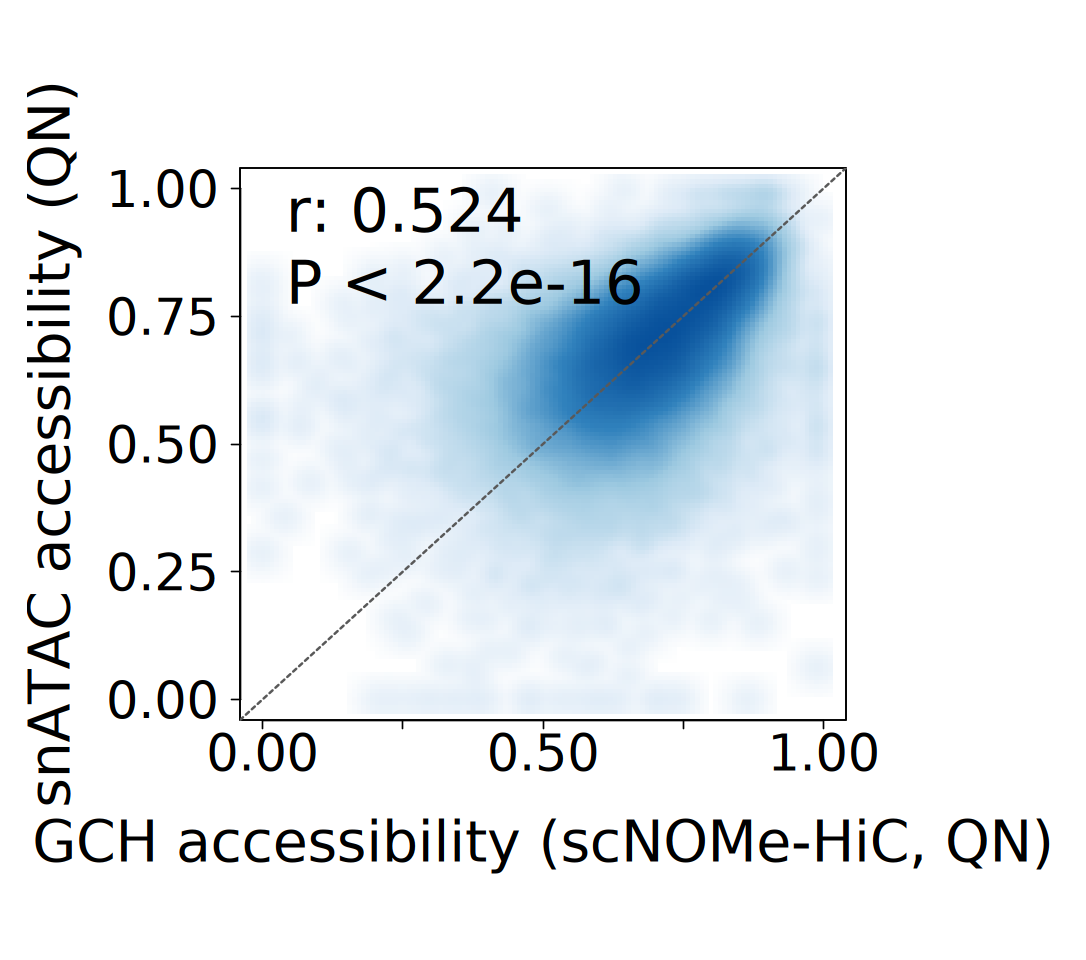

In [2]:
# Per-peak GCH vs snATAC accessibility -- quantile-normalized, ALL peaks.
stopifnot(exists("d"))
z <- qn01(d$GCH, d$snATAC)
draw_scatter(z$x, z$y,
             "GCH accessibility (scNOMe-HiC, QN)",
             "snATAC accessibility (QN)",
             file.path(FIG, "R_gch_vs_snatac_qnorm"))